# TP4 — Architecture Transformer
**Implémentation avec PyTorch — RNN, LSTM, Transformer, GPT et BERT**

Ce notebook suit le support du professeur et les trois exercices de fin. Exécuter les cellules dans l’ordre. Les modèles séquentiels sont entraînés sur CPU si aucun GPU CUDA n’est disponible.

## 0. Imports et configuration

In [1]:
import os, zipfile, math, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("Device :", device)

PyTorch : 2.14.1+cpu
Device : cpu


## Première partie — Série temporelle sinusoïdale
### 1. Génération et préparation des données
On utilise 200 points entre 0 et 20. Chaque entrée contient 10 valeurs et la cible est la valeur suivante. Le découpage chronologique reprend celui du support : 150 exemples pour entraîner et 40 pour tester.

In [2]:
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
X = torch.stack([serie[i:i+longueur_sequence] for i in range(len(serie)-longueur_sequence)])
y = torch.stack([serie[i+longueur_sequence] for i in range(len(serie)-longueur_sequence)])
X = X.unsqueeze(-1)
y = y.unsqueeze(-1)
X_train, y_train = X[:150].to(device), y[:150].to(device)
X_test, y_test = X[150:].to(device), y[150:].to(device)
print("X:", X.shape, "y:", y.shape)
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

X: torch.Size([190, 10, 1]) y: torch.Size([190, 1])
X_train: torch.Size([150, 10, 1]) y_train: torch.Size([150, 1])
X_test: torch.Size([40, 10, 1]) y_test: torch.Size([40, 1])


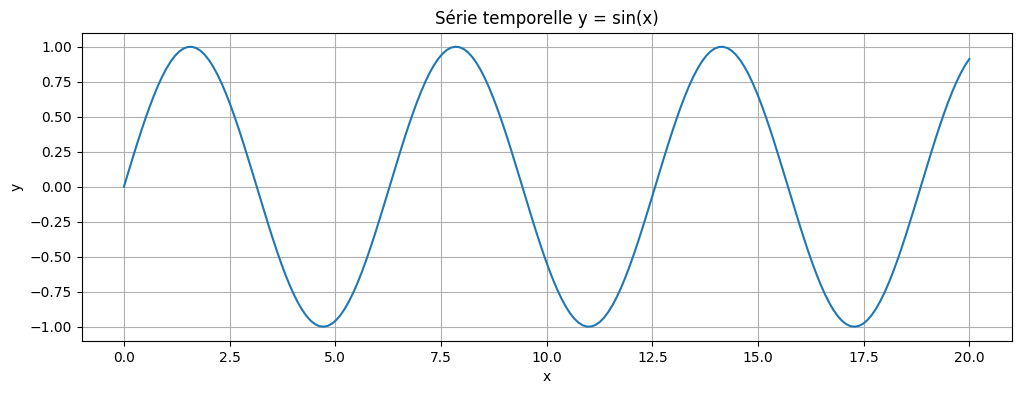

In [3]:
plt.figure(figsize=(12,4))
plt.plot(periode.numpy(), serie.numpy())
plt.title("Série temporelle y = sin(x)")
plt.xlabel("x"); plt.ylabel("y"); plt.grid(); plt.show()

### 2. RNN — création, entraînement et test

In [4]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)
    def forward(self, x):
        etats, _ = self.rnn(x)
        return self.sortie(etats[:, -1, :])

modele_rnn = SimpleRNN().to(device)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_rnn.parameters(), lr=0.01)
modele_rnn.train()
for epoch in range(300):
    pred = modele_rnn(X_train)
    perte = critere(pred, y_train)
    optimiseur.zero_grad(); perte.backward(); optimiseur.step()
    if (epoch+1)%50==0: print(f"Epoch {epoch+1:3d} | Erreur : {perte.item():.6f}")
modele_rnn.eval()
with torch.no_grad():
    pred_rnn = modele_rnn(X_test)
    print("MSE test :", critere(pred_rnn,y_test).item())
    print("Réel :", y_test[0].item(), "Prédit :", pred_rnn[0].item())

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025
MSE test : 2.762989970506169e-05
Réel : -0.3638884127140045 Prédit : -0.36008596420288086


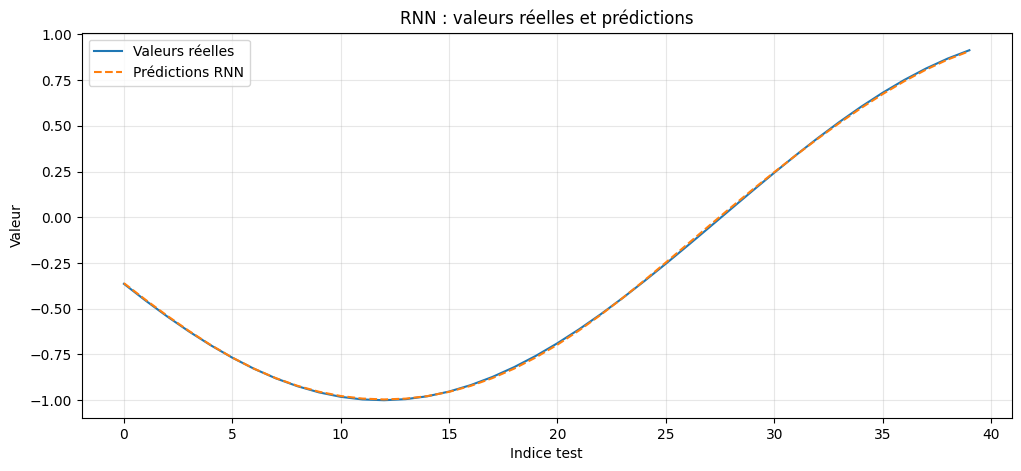

In [5]:
plt.figure(figsize=(12,5))
plt.plot(y_test.cpu().numpy().ravel(), label="Valeurs réelles")
plt.plot(pred_rnn.cpu().numpy().ravel(), "--", label="Prédictions RNN")
plt.title("RNN : valeurs réelles et prédictions"); plt.xlabel("Indice test"); plt.ylabel("Valeur")
plt.legend(); plt.grid(alpha=.3); plt.show()

### 3. LSTM — création, entraînement et test

In [6]:
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=16, num_layers=1, batch_first=True)
        self.sortie = nn.Linear(16,1)
    def forward(self,x):
        etats, (h_final,c_final) = self.lstm(x)
        return self.sortie(etats[:,-1,:])

modele_lstm = SimpleLSTM().to(device)
optimiseur_lstm = torch.optim.Adam(modele_lstm.parameters(),lr=0.01)
for epoch in range(300):
    modele_lstm.train(); pred=modele_lstm(X_train); perte=critere(pred,y_train)
    optimiseur_lstm.zero_grad(); perte.backward(); optimiseur_lstm.step()
    if (epoch+1)%50==0: print(f"Epoch {epoch+1:3d} | Erreur : {perte.item():.6f}")
modele_lstm.eval()
with torch.no_grad():
    pred_lstm=modele_lstm(X_test)
    print("MSE test :",critere(pred_lstm,y_test).item())
    print("Réel :",y_test[0].item(),"Prédit :",pred_lstm[0].item())

Epoch  50 | Erreur : 0.002550
Epoch 100 | Erreur : 0.000239
Epoch 150 | Erreur : 0.000019
Epoch 200 | Erreur : 0.000014
Epoch 250 | Erreur : 0.000012
Epoch 300 | Erreur : 0.000010
MSE test : 9.920668162521906e-06
Réel : -0.3638884127140045 Prédit : -0.36191970109939575


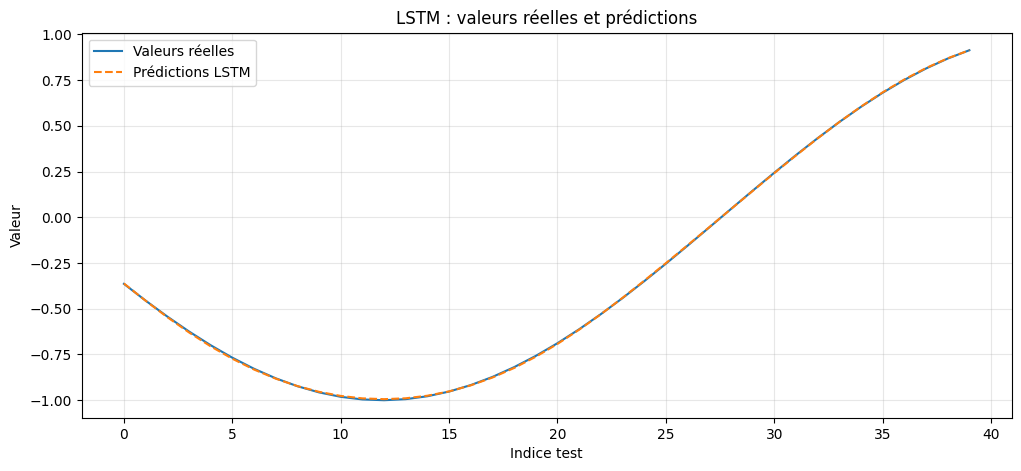

In [7]:
plt.figure(figsize=(12,5))
plt.plot(y_test.cpu().numpy().ravel(),label="Valeurs réelles")
plt.plot(pred_lstm.cpu().numpy().ravel(),"--",label="Prédictions LSTM")
plt.title("LSTM : valeurs réelles et prédictions"); plt.xlabel("Indice test"); plt.ylabel("Valeur")
plt.legend(); plt.grid(alpha=.3); plt.show()

### 4. Mini-Transformer — prédiction de la valeur suivante

In [8]:
class MiniTransformer(nn.Module):
    def __init__(self,longueur_max=10):
        super().__init__(); dimension=16
        self.projection=nn.Linear(1,dimension)
        self.positions=nn.Embedding(longueur_max,dimension)
        couche=nn.TransformerEncoderLayer(d_model=dimension,nhead=2,dim_feedforward=32,dropout=0.0,batch_first=True)
        self.encodeur=nn.TransformerEncoder(couche,num_layers=1)
        self.sortie=nn.Linear(dimension,1)
    def forward(self,x):
        longueur=x.size(1)
        x=self.projection(x)
        indices=torch.arange(longueur,device=x.device)
        x=x+self.positions(indices).unsqueeze(0)
        representations=self.encodeur(x)
        return self.sortie(representations[:,-1,:])

modele_transformer=MiniTransformer(longueur_sequence).to(device)
optimiseur_tr= torch.optim.Adam(modele_transformer.parameters(),lr=0.01)
for epoch in range(300):
    modele_transformer.train(); pred=modele_transformer(X_train); perte=critere(pred,y_train)
    optimiseur_tr.zero_grad(); perte.backward(); optimiseur_tr.step()
    if (epoch+1)%50==0: print(f"Epoch {epoch+1:3d} | Erreur : {perte.item():.6f}")
modele_transformer.eval()
with torch.no_grad():
    pred_tr=modele_transformer(X_test)
    print("MSE test :",critere(pred_tr,y_test).item())
    print("Réel :",y_test[0].item(),"Prédit :",pred_tr[0].item())

Epoch  50 | Erreur : 0.000699
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.001304
Epoch 200 | Erreur : 0.000111
Epoch 250 | Erreur : 0.000061
Epoch 300 | Erreur : 0.000038
MSE test : 5.324220910551958e-05
Réel : -0.3638884127140045 Prédit : -0.3693964183330536


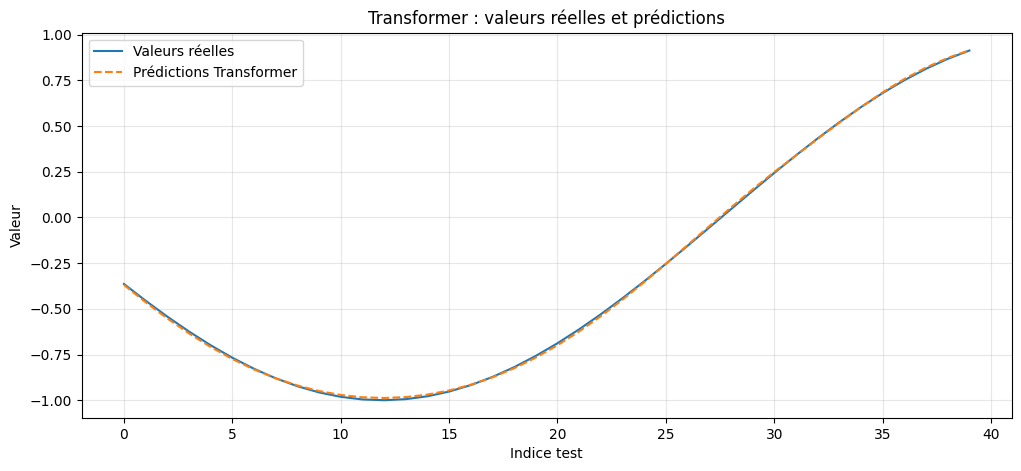

Comparaison MSE — RNN: 2.762989970506169e-05 LSTM: 9.920668162521906e-06 Transformer: 5.324220910551958e-05


In [9]:
plt.figure(figsize=(12,5))
plt.plot(y_test.cpu().numpy().ravel(),label="Valeurs réelles")
plt.plot(pred_tr.cpu().numpy().ravel(),"--",label="Prédictions Transformer")
plt.title("Transformer : valeurs réelles et prédictions"); plt.xlabel("Indice test"); plt.ylabel("Valeur")
plt.legend(); plt.grid(alpha=.3); plt.show()
print("Comparaison MSE — RNN:",critere(pred_rnn,y_test).item(),"LSTM:",critere(pred_lstm,y_test).item(),"Transformer:",critere(pred_tr,y_test).item())

### 5. GPT-2 — génération de texte
GPT est autorégressif : il prédit la suite à partir des tokens précédents. Le modèle préentraîné est téléchargé depuis Hugging Face au premier lancement (connexion Internet requise).

In [10]:
from transformers import AutoTokenizer, AutoModelForCausalLM
nom_modele = "gpt2"
tokenizer_gpt = AutoTokenizer.from_pretrained(nom_modele)
modele_gpt = AutoModelForCausalLM.from_pretrained(nom_modele)
modele_gpt.eval()
texte = "Artificial intelligence can help people"
entrees = tokenizer_gpt(texte,return_tensors="pt")
with torch.no_grad():
    sortie = modele_gpt.generate(**entrees,max_new_tokens=50,do_sample=True,temperature=0.8,top_p=0.9,pad_token_id=tokenizer_gpt.eos_token_id)
print(tokenizer_gpt.decode(sortie[0],skip_special_tokens=True))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

c:\Users\PC\Desktop\Architecture Transformer\transformer_env\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\PC\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Artificial intelligence can help people find solutions to a myriad of problems. It could be an option for the public at large.

In the meantime, the question is whether the AI will be able to provide us with a new way of interacting with the world.


### 6. BERT — prédiction d’un mot masqué
BERT est bidirectionnel : il utilise le contexte à gauche et à droite du token masqué.

In [11]:
from transformers import AutoTokenizer, AutoModelForMaskedLM
nom_modele_bert="bert-base-multilingual-cased"
tokenizer_bert=AutoTokenizer.from_pretrained(nom_modele_bert)
modele_bert=AutoModelForMaskedLM.from_pretrained(nom_modele_bert)
modele_bert.eval()
texte="Paris est la "+tokenizer_bert.mask_token+" de la France."
entrees=tokenizer_bert(texte,return_tensors="pt")
position=(entrees["input_ids"][0]==tokenizer_bert.mask_token_id).nonzero(as_tuple=True)[0].item()
with torch.no_grad(): sortie=modele_bert(**entrees)
scores=sortie.logits[0,position,:]
prob=torch.softmax(scores,dim=-1)
valeurs,indices=torch.topk(prob,k=5)
print("Phrase :",texte)
for p,idx in zip(valeurs,indices):
    token=tokenizer_bert.decode([idx.item()]).strip()
    print(f"{p.item():.2%} | {texte.replace(tokenizer_bert.mask_token,token)}")

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

c:\Users\PC\Desktop\Architecture Transformer\transformer_env\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\PC\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Phrase : Paris est la [MASK] de la France.
36.32% | Paris est la capitale de la France.
21.09% | Paris est la ville de la France.
3.16% | Paris est la Cité de la France.
1.67% | Paris est la préfecture de la France.
1.64% | Paris est la banlieue de la France.


## Deuxième partie — Exercices

## Exercice 1 — Prédiction de la consommation électrique avec un Transformer
Utiliser les 24 dernières heures de consommation moyenne horaire pour prédire l’heure suivante. Le fichier ZIP fourni doit être placé à côté du notebook ou décompressé dans le dossier `data/`.

In [13]:
# Recherche et extraction du fichier de données fourni
zip_candidates=list(Path('.').glob('*.zip')) + list(Path('data').glob('*.zip'))
if zip_candidates:
    with zipfile.ZipFile(zip_candidates[0]) as z: z.extractall('data')
chemins=list(Path('data').rglob('household_power_consumption.txt'))
if not chemins:
    raise FileNotFoundError("Placez household_power_consumption.txt ou le ZIP fourni dans le dossier du notebook ou data/.")
chemin=str(chemins[0]); print("Fichier utilisé :",chemin)
df=pd.read_csv(chemin,sep=';',na_values=['?'],low_memory=False)
df['datetime']=pd.to_datetime(df['Date']+' '+df['Time'],format='%d/%m/%Y %H:%M:%S')
puissance=pd.to_numeric(df['Global_active_power'],errors='coerce')
puissance.index=pd.DatetimeIndex(df['datetime'])
horaire=puissance.resample('h').agg(['mean','count'])
serie_energie=horaire['mean'].where(horaire['count']>=45)
n=len(serie_energie); fin_train=int(.70*n); fin_val=int(.85*n)
moyenne=serie_energie.iloc[:fin_train].mean(); ecart_type=serie_energie.iloc[:fin_train].std()
valeurs=((serie_energie-moyenne)/ecart_type).to_numpy()
fenetre=24; XX=[]; yy=[]; dates=[]
for i in range(fenetre,n):
    seq=valeurs[i-fenetre:i]; cible=valeurs[i]
    if np.isfinite(seq).all() and np.isfinite(cible): XX.append(seq); yy.append(cible); dates.append(i)
XX=torch.tensor(np.array(XX),dtype=torch.float32).unsqueeze(-1)
yy=torch.tensor(np.array(yy),dtype=torch.float32).unsqueeze(-1)
dates=np.array(dates)
train_mask=dates<fin_train; val_mask=(dates>=fin_train)&(dates<fin_val); test_mask=dates>=fin_val
from torch.utils.data import TensorDataset,DataLoader
train_loader=DataLoader(TensorDataset(XX[train_mask],yy[train_mask]),batch_size=64,shuffle=True)
val_loader=DataLoader(TensorDataset(XX[val_mask],yy[val_mask]),batch_size=64)
test_loader=DataLoader(TensorDataset(XX[test_mask],yy[test_mask]),batch_size=64)
print('Séquences train/val/test :',train_mask.sum(),val_mask.sum(),test_mask.sum())

Fichier utilisé : data\household_power_consumption\household_power_consumption.txt
Séquences train/val/test : 23805 5054 4932


In [14]:
class EnergyTransformer(nn.Module):
    def __init__(self):
        super().__init__(); d=32
        self.projection=nn.Linear(1,d); self.positions=nn.Embedding(24,d)
        couche=nn.TransformerEncoderLayer(d_model=d,nhead=4,dim_feedforward=128,dropout=.1,batch_first=True)
        self.encodeur=nn.TransformerEncoder(couche,num_layers=2); self.sortie=nn.Linear(d,1)
    def forward(self,x):
        pos=torch.arange(x.size(1),device=x.device)
        h=self.projection(x)+self.positions(pos).unsqueeze(0)
        h=self.encodeur(h)
        return self.sortie(h[:,-1,:])

energy_model=EnergyTransformer().to(device); opt=torch.optim.Adam(energy_model.parameters(),lr=.001)
best=float('inf'); best_state=None
for epoch in range(20):
    energy_model.train(); total=0
    for xb,yb in train_loader:
        xb,yb=xb.to(device),yb.to(device); opt.zero_grad(); pred=energy_model(xb); loss=nn.functional.mse_loss(pred,yb); loss.backward(); opt.step(); total+=loss.item()*len(xb)
    energy_model.eval(); val_loss=0; count=0
    with torch.no_grad():
        for xb,yb in val_loader:
            xb,yb=xb.to(device),yb.to(device); val_loss+=nn.functional.mse_loss(energy_model(xb),yb,reduction='sum').item(); count+=len(xb)
    val_loss/=max(count,1); print(f'Epoch {epoch+1:02d} | train MSE {total/len(train_loader.dataset):.4f} | val MSE {val_loss:.4f}')
    if val_loss<best: best=val_loss; best_state={k:v.detach().cpu().clone() for k,v in energy_model.state_dict().items()}
energy_model.load_state_dict(best_state)

Epoch 01 | train MSE 0.4735 | val MSE 0.3996
Epoch 02 | train MSE 0.4314 | val MSE 0.3915
Epoch 03 | train MSE 0.4235 | val MSE 0.3931
Epoch 04 | train MSE 0.4202 | val MSE 0.3909
Epoch 05 | train MSE 0.4171 | val MSE 0.3881
Epoch 06 | train MSE 0.4131 | val MSE 0.3850
Epoch 07 | train MSE 0.4101 | val MSE 0.3857
Epoch 08 | train MSE 0.4114 | val MSE 0.3822
Epoch 09 | train MSE 0.4080 | val MSE 0.3844
Epoch 10 | train MSE 0.4069 | val MSE 0.3850
Epoch 11 | train MSE 0.4020 | val MSE 0.3877
Epoch 12 | train MSE 0.4037 | val MSE 0.3829
Epoch 13 | train MSE 0.4028 | val MSE 0.3905
Epoch 14 | train MSE 0.4015 | val MSE 0.3851
Epoch 15 | train MSE 0.4005 | val MSE 0.3849
Epoch 16 | train MSE 0.4000 | val MSE 0.3872
Epoch 17 | train MSE 0.4007 | val MSE 0.3834
Epoch 18 | train MSE 0.3971 | val MSE 0.3802
Epoch 19 | train MSE 0.3963 | val MSE 0.3964
Epoch 20 | train MSE 0.3957 | val MSE 0.3829


<All keys matched successfully>

Transformer MAE/RMSE kW : (np.float64(0.35410740792484807), np.float64(0.49180097777017345))
Persistance MAE/RMSE kW : (np.float64(0.3891981019426929), np.float64(0.5883847071313124))
Référence 24h MAE/RMSE kW : (np.float64(0.513277162006016), np.float64(0.7638759711757405))


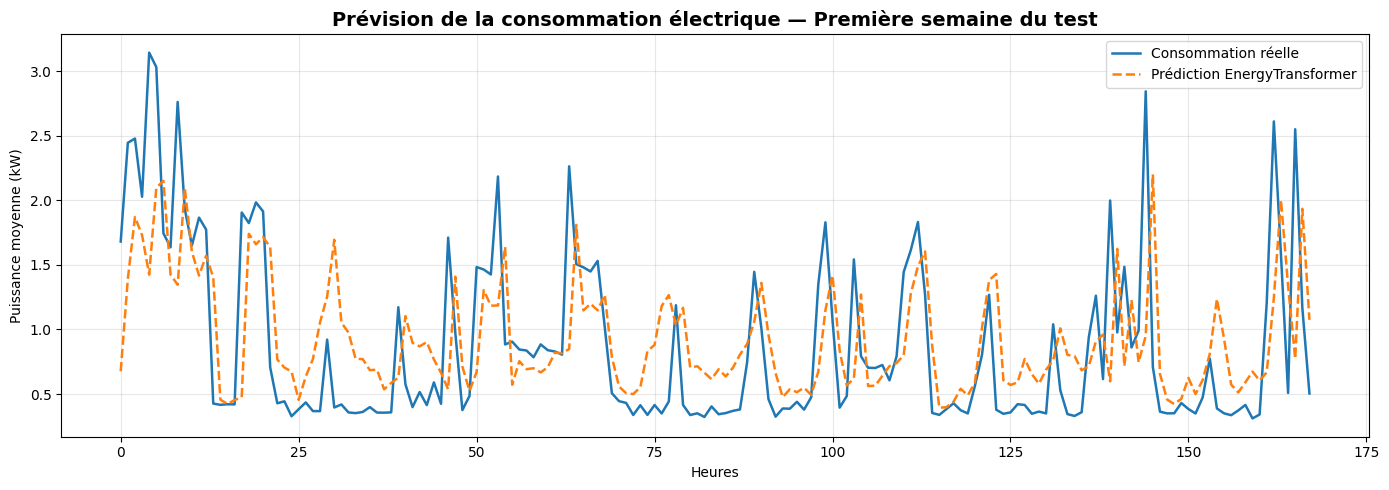

In [25]:
energy_model.eval(); pred_list=[]; true_list=[]; input_last=[]; input_day=[]
with torch.no_grad():
    for xb,yb in test_loader:
        xb=xb.to(device); pred_list.extend(energy_model(xb).cpu().numpy().ravel()); true_list.extend(yb.numpy().ravel())
        input_last.extend(xb[:,-1,0].cpu().numpy()); input_day.extend(xb[:,0,0].cpu().numpy())
real=np.array(true_list)*ecart_type+moyenne; pred=np.array(pred_list)*ecart_type+moyenne
pers=np.array(input_last)*ecart_type+moyenne
daily=np.array(input_day)*ecart_type+moyenne
def metrics(a,b): return np.mean(np.abs(a-b)),np.sqrt(np.mean((a-b)**2))
print('Transformer MAE/RMSE kW :',metrics(real,pred))
print('Persistance MAE/RMSE kW :',metrics(real,pers))
print('Référence 24h MAE/RMSE kW :',metrics(real,daily))

# Visualisation : consommation réelle vs prédiction
plt.figure(figsize=(14, 5))

plt.plot(
    real[:168],
    label="Consommation réelle",
    linewidth=1.8
)

plt.plot(
    pred[:168],
    label="Prédiction EnergyTransformer",
    linewidth=1.8,
    linestyle="--"
)

plt.title(
    "Prévision de la consommation électrique — Première semaine du test",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Heures")
plt.ylabel("Puissance moyenne (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Export du graphique
plt.savefig(
    "results/plots/energy_forecasting.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Exercice 1 — Questions de réflexion
Répondre à partir des métriques obtenues :
1. Le Transformer améliore-t-il les deux références ?
2. Une fenêtre de 168 heures pourrait-elle mieux capturer les habitudes hebdomadaires ?
3. Quel serait l’intérêt d’ajouter l’heure et le jour de la semaine ?
4. Pourquoi normaliser uniquement avec les données d’entraînement ?
5. Comment adapter la préparation pour prédire une énergie consommée en kWh ?

### Exercice 1 — Questions de réflexion

**1. Le Transformer améliore-t-il les deux références ?**

Oui. Les résultats expérimentaux montrent que le Transformer obtient les meilleures performances parmi les trois méthodes comparées.

- Transformer : MAE = 0.3541 kW, RMSE = 0.4918 kW.
- Persistance : MAE = 0.3892 kW, RMSE = 0.5884 kW.
- Référence 24h : MAE = 0.5133 kW, RMSE = 0.7639 kW.

Le Transformer réduit la MAE d'environ 9 % par rapport à la persistance et de 31 % par rapport à la référence 24h. Il réduit également la RMSE d'environ 16 % et 36 % respectivement.

On peut donc conclure que le Transformer apprend mieux les dépendances temporelles de la consommation électrique que les deux références utilisées.

**2. Une fenêtre de 168 heures pourrait-elle mieux capturer les habitudes hebdomadaires ?**

Oui. Une fenêtre de 168 heures correspond à sept jours de données horaires. Elle permettrait au Transformer d'observer les habitudes de consommation sur une semaine complète.

Cela pourrait l'aider à identifier les différences entre les jours ouvrables et le week-end, ainsi que les habitudes qui se répètent chaque semaine.

Cependant, une fenêtre plus longue augmente le nombre de données à traiter et le coût de calcul. Il faudrait donc réaliser une nouvelle expérimentation pour vérifier si cette modification améliore réellement les performances.

**3. Quel serait l'intérêt d'ajouter l'heure et le jour de la semaine ?**

L'ajout de ces informations permettrait au modèle de mieux comprendre les comportements périodiques de consommation.

- L'heure permet d'identifier les périodes de forte et de faible consommation.
- Le jour de la semaine permet de distinguer les habitudes des jours ouvrables de celles du week-end.

Ces variables temporelles apportent un contexte supplémentaire au modèle et pourraient améliorer la précision des prédictions.

**4. Pourquoi normaliser uniquement avec les données d'entraînement ?**

La normalisation doit être calculée uniquement à partir des données d'entraînement afin d'éviter la fuite de données (*Data Leakage*).

Si les données de validation ou de test sont utilisées pour calculer les paramètres de normalisation, le modèle reçoit indirectement des informations provenant de données qu'il est censé ne pas connaître pendant l'entraînement.

On calcule donc la moyenne et l'écart-type sur les données d'entraînement, puis on applique les mêmes paramètres aux données de validation et de test.

Cette méthode garantit une évaluation plus fiable de la capacité de généralisation du modèle.

**5. Comment adapter la préparation pour prédire une énergie consommée en kWh ?**

Il faudrait adapter la variable cible pour représenter l'énergie consommée au lieu de la puissance moyenne exprimée en kW.

Pour une mesure horaire, l'énergie consommée peut être calculée à partir de la puissance moyenne :

E (kWh) = P moyenne (kW) × durée (h).

Pour une période d'une heure, la valeur numérique en kWh correspond donc à la puissance moyenne en kW sur cette heure.

Il faudrait également adapter le prétraitement des données, vérifier les unités, préparer les séquences et entraîner le modèle avec cette nouvelle variable cible.

Enfin, les performances devraient être évaluées en kWh à l'aide des métriques MAE et RMSE.

## Exercice 2 — Implémenter un mini-GPT
Modèle autorégressif caractère par caractère, entraîné depuis zéro. On crée un petit corpus local afin que le notebook soit autonome.

In [16]:
corpus = ("Les modèles de langage apprennent des régularités dans les séquences. "
          "Un Transformer utilise le mécanisme d'attention pour relier les éléments. "
          "Un modèle GPT prédit le prochain caractère ou token à partir du contexte précédent. ")*100
Path('corpus.txt').write_text(corpus,encoding='utf-8')
caracteres=sorted(set(corpus)); stoi={ch:i for i,ch in enumerate(caracteres)}; itos={i:ch for ch,i in stoi.items()}
tokens=torch.tensor([stoi[ch] for ch in corpus],dtype=torch.long)
vocab_size=len(caracteres); longueur=64
# Séparation chronologique train/test
split=int(.9*len(tokens)); train_tokens=tokens[:split]; val_tokens=tokens[split:]
def get_batch(source,batch_size=32):
    starts=torch.randint(0,len(source)-longueur-1,(batch_size,))
    x=torch.stack([source[i:i+longueur] for i in starts]); y=torch.stack([source[i+1:i+longueur+1] for i in starts])
    return x.to(device),y.to(device)
print('Taille vocabulaire :',vocab_size)

Taille vocabulaire : 31


In [17]:
class GPTBlock(nn.Module):
    def __init__(self,d=64,heads=4):
        super().__init__(); self.ln1=nn.LayerNorm(d); self.attn=nn.MultiheadAttention(d,heads,batch_first=True)
        self.ln2=nn.LayerNorm(d); self.mlp=nn.Sequential(nn.Linear(d,256),nn.GELU(),nn.Linear(256,d))
    def forward(self,x):
        T=x.size(1); mask=torch.triu(torch.ones(T,T,device=x.device,dtype=torch.bool),diagonal=1)
        h=self.ln1(x); a,_=self.attn(h,h,h,attn_mask=mask,need_weights=False); x=x+a
        return x+self.mlp(self.ln2(x))
class MiniGPT(nn.Module):
    def __init__(self,vocab_size,block_size=64):
        super().__init__(); self.token_emb=nn.Embedding(vocab_size,64); self.pos_emb=nn.Embedding(block_size,64)
        self.blocks=nn.Sequential(GPTBlock(),GPTBlock()); self.ln=nn.LayerNorm(64); self.head=nn.Linear(64,vocab_size)
    def forward(self,idx):
        B,T=idx.shape; pos=torch.arange(T,device=idx.device)
        x=self.token_emb(idx)+self.pos_emb(pos)[None,:,:]; x=self.blocks(x); return self.head(self.ln(x))
    @torch.no_grad()
    def generate(self,idx,max_new_tokens,temperature=1.0):
        self.eval()
        for _ in range(max_new_tokens):
            context=idx[:,-64:]; logits=self(context)[:,-1,:]/temperature
            probs=torch.softmax(logits,dim=-1); next_id=torch.multinomial(probs,1); idx=torch.cat([idx,next_id],dim=1)
        return idx
gpt=MiniGPT(vocab_size).to(device); opt_gpt=torch.optim.AdamW(gpt.parameters(),lr=3e-4)
for step in range(1000):
    gpt.train(); xb,yb=get_batch(train_tokens); logits=gpt(xb); loss=nn.functional.cross_entropy(logits.reshape(-1,vocab_size),yb.reshape(-1))
    opt_gpt.zero_grad(); loss.backward(); opt_gpt.step()
    if (step+1)%200==0: print('Step',step+1,'loss',round(loss.item(),4))

Step 200 loss 1.7199
Step 400 loss 0.8036
Step 600 loss 0.2325
Step 800 loss 0.1083
Step 1000 loss 0.072


In [26]:

import textwrap

amorce = "Les modèles"
idx = torch.tensor(
    [[stoi[ch] for ch in amorce]],
    dtype=torch.long,
    device=device
)

for temperature in [0.5, 1.0, 1.5]:
    sortie = gpt.generate(
        idx.clone(), 200, temperature=temperature
    )[0].cpu().tolist()

    texte_genere = ''.join(itos[i] for i in sortie)

    print(f"\n--- Température {temperature} ---\n")
    print(textwrap.fill(texte_genere, width=100))
    print("-" * 100)



--- Température 0.5 ---

Les modèles de langage apprennent des régularités dans les séquences. Un Transformer utilise le
mécanisme d'attention pour relier les éléments. Un modèle GPT prédit le prochain caractère ou token
à partir du con
----------------------------------------------------------------------------------------------------

--- Température 1.0 ---

Les modèles de langage apprennent des régularités dans les s séquencences. Un TransTrmer utisfor
utilise le mécanisme d'atttention pour r relies léléments. Un Trs modèle GPT préchaitin daite
chacaractère on tèr
----------------------------------------------------------------------------------------------------

--- Température 1.5 ---

Les modèles de langage apdenct rexte de préent den. Les modes dèlan u qu re rartère du orégkents.
ulipUn T Tr mèrécéèlenies dèlan GPT répres. darn les GPTrule prédit. hait   Un cte tokdèr . Les
modèlengage apppr
-------------------------------------------------------------------------------------

**Vérification du masque causal** : changer un caractère futur ne doit pas modifier les logits des positions antérieures.

In [19]:
gpt.eval(); x,_=get_batch(val_tokens,1); x2=x.clone(); x2[0,-1]=(x2[0,-1]+1)%vocab_size
with torch.no_grad(): a=gpt(x); b=gpt(x2)
print('Différence max sur les positions précédentes :',(a[:,:-1]-b[:,:-1]).abs().max().item())

Différence max sur les positions précédentes : 0.0


### Exercice 2 — Questions
1. Que se passe-t-il si le masque causal est supprimé ?
2. Quel effet la température a-t-elle sur la génération ?
3. Pourquoi décaler les cibles d’une position ?

### Exercice 2 — Réponses aux questions

**1. Que se passe-t-il si le masque causal est supprimé ?**

Si le masque causal est supprimé, le modèle peut accéder aux caractères futurs pendant le calcul de l'attention.

Cela crée une fuite d'information, car le modèle peut utiliser des éléments qui ne sont normalement pas disponibles au moment de prédire le prochain caractère.

Le modèle ne respecte alors plus le fonctionnement autorégressif de GPT. Il risque d'apprendre une tâche différente de celle attendue et ses performances d'entraînement peuvent devenir artificiellement meilleures.

**2. Quel effet la température a-t-elle sur la génération ?**

La température contrôle le niveau d'aléatoire dans la sélection du prochain caractère.

- Une température faible (0.5) favorise les caractères les plus probables et produit généralement un texte plus cohérent et prévisible.
- Une température de 1.0 conserve la distribution originale des probabilités et permet une génération plus variée.
- Une température élevée (1.5) augmente l'aléatoire et peut produire des textes moins cohérents.

Dans notre expérience, la température 0.5 donne la génération la plus structurée, tandis que 1.5 produit davantage de caractères et de mots incohérents.

**3. Pourquoi décaler les cibles d'une position ?**

Dans un modèle GPT, l'objectif est de prédire le prochain caractère ou token à partir des éléments précédents.

On décale donc les séquences cibles d'une position par rapport aux séquences d'entrée.

Par exemple :

- Entrée : "BONJ"
- Cible : "ONJO"

Chaque caractère de la séquence d'entrée sert à prédire le caractère suivant.

Ce décalage permet d'entraîner le modèle à apprendre la prédiction autorégressive, qui constitue le principe fondamental du fonctionnement de GPT.

## Exercice 3 — Implémenter un mini-BERT
Modèle bidirectionnel entraîné à retrouver des mots masqués dans un petit corpus français.

In [20]:
PAD,UNK,CLS,SEP,MASK=0,1,2,3,4
phrases=[
"le chat dort sur le canapé", "le chien joue dans le jardin", "la voiture roule sur la route",
"les étudiants apprennent le traitement automatique du langage", "le professeur explique les réseaux de neurones",
"le transformer utilise le mécanisme attention", "les données permettent entraîner un modèle",
"la machine apprend à partir des exemples", "le soleil brille dans le ciel", "les enfants lisent un livre"
]*30
phrases=[p.lower().split() for p in phrases]
vocab={"[PAD]":PAD,"[UNK]":UNK,"[CLS]":CLS,"[SEP]":SEP,"[MASK]":MASK}
for p in phrases:
    for w in p:
        if w not in vocab: vocab[w]=len(vocab)
id_to_word={i:w for w,i in vocab.items()}; V=len(vocab); max_len=32
def encode(p):
    ids=[CLS]+[vocab.get(w,UNK) for w in p]+[SEP]; return (ids+[PAD]*max(0,max_len-len(ids)))[:max_len]
all_ids=torch.tensor([encode(p) for p in phrases],dtype=torch.long)
perm=torch.randperm(len(all_ids)); cut=int(.8*len(perm)); train_ids=all_ids[perm[:cut]]; val_ids=all_ids[perm[cut:]]
print('Vocabulaire:',V,'Train:',train_ids.shape,'Validation:',val_ids.shape)

Vocabulaire: 51 Train: torch.Size([240, 32]) Validation: torch.Size([60, 32])


In [21]:
def corrupt_batch(original):
    inp=original.clone(); selected=torch.zeros_like(original,dtype=torch.bool)
    special=(original==PAD)|(original==UNK)|(original==CLS)|(original==SEP)|(original==MASK)
    for i in range(original.size(0)):
        eligible=(~special[i]).nonzero(as_tuple=True)[0]
        if len(eligible)==0: continue
        count=max(1,int(round(.15*len(eligible))))
        chosen=eligible[torch.randperm(len(eligible),device=eligible.device)[:count]]
        selected[i,chosen]=True
        for pos in chosen:
            r=random.random()
            if r<.8: inp[i,pos]=MASK
            elif r<.9: inp[i,pos]=random.choice(list(range(5,V)))
    labels=original.clone(); labels[~selected]=-100
    return inp,labels,selected
class MiniBERT(nn.Module):
    def __init__(self,vocab_size,max_len=32):
        super().__init__(); d=64
        self.tok=nn.Embedding(vocab_size,d,padding_idx=PAD); self.pos=nn.Embedding(max_len,d)
        layer=nn.TransformerEncoderLayer(d_model=d,nhead=4,dim_feedforward=256,dropout=.1,batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2); self.norm=nn.LayerNorm(d); self.head=nn.Linear(d,vocab_size)
    def forward(self,ids):
        pos=torch.arange(ids.size(1),device=ids.device); x=self.tok(ids)+self.pos(pos)[None,:,:]
        pad_mask=ids.eq(PAD); h=self.encoder(x,src_key_padding_mask=pad_mask); return self.head(self.norm(h))
bert=MiniBERT(V).to(device); opt_bert=torch.optim.AdamW(bert.parameters(),lr=1e-3)
for epoch in range(30):
    bert.train(); order=torch.randperm(len(train_ids)); total=0
    for start in range(0,len(order),16):
        batch=train_ids[order[start:start+16]].to(device); corrupted,labels,selected=corrupt_batch(batch)
        logits=bert(corrupted); loss=nn.functional.cross_entropy(logits.reshape(-1,V),labels.to(device).reshape(-1),ignore_index=-100)
        opt_bert.zero_grad(); loss.backward(); opt_bert.step(); total+=loss.item()
    if (epoch+1)%5==0: print(f'Epoch {epoch+1:02d} | loss {total/max(1,math.ceil(len(order)/16)):.4f}')

Epoch 05 | loss 1.4628
Epoch 10 | loss 0.4228
Epoch 15 | loss 0.1510
Epoch 20 | loss 0.0829
Epoch 25 | loss 0.0597
Epoch 30 | loss 0.0366


In [27]:

# Évaluation du Mini-BERT
bert.eval()
correct = 0
count = 0

with torch.no_grad():
    for start in range(0, len(val_ids), 16):
        batch = val_ids[start:start+16].to(device)
        corrupted, labels, selected = corrupt_batch(batch)
        logits = bert(corrupted)
        pred = logits.argmax(-1)
        correct += (pred[selected] == batch[selected]).sum().item()
        count += selected.sum().item()

accuracy = correct / max(count, 1)

print("=" * 65)
print("              ÉVALUATION DU MINI-BERT")
print("=" * 65)
print(f"\nAccuracy sur les tokens masqués : {accuracy * 100:.1f} %")
print(f"Nombre de tokens évalués : {count}")

# Exemples de prédictions
batch = val_ids[:4].to(device)
corrupted, labels, selected = corrupt_batch(batch)

with torch.no_grad():
    probs = torch.softmax(bert(corrupted), dim=-1)

print("\n" + "=" * 65)
print("              EXEMPLES DE PRÉDICTIONS")
print("=" * 65)

for i in range(len(batch)):
    positions = selected[i].nonzero(as_tuple=True)[0]

    for pos in positions[:2]:
        top = torch.topk(probs[i, pos], 3).indices.tolist()
        original = id_to_word[batch[i, pos].item()]
        suggestions = [id_to_word[t] for t in top]

        print(f"\nMot original  : {original}")
        print(f"Suggestions   : {' | '.join(suggestions)}")
        print("-" * 45)

print("\nÉvaluation terminée.")


              ÉVALUATION DU MINI-BERT

Accuracy sur les tokens masqués : 100.0 %
Nombre de tokens évalués : 60

              EXEMPLES DE PRÉDICTIONS

Mot original  : canapé
Suggestions   : canapé | partir | dans
---------------------------------------------

Mot original  : machine
Suggestions   : machine | à | enfants
---------------------------------------------

Mot original  : le
Suggestions   : le | la | transformer
---------------------------------------------

Mot original  : roule
Suggestions   : roule | sur | transformer
---------------------------------------------

Évaluation terminée.


### Exercice 3 — Questions
1. Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?
2. Pourquoi calculer la perte uniquement sur les positions sélectionnées ?
3. Pourquoi ce modèle ne génère-t-il pas directement du texte comme GPT ?

### Exercice 3 — Réponses aux questions

**1. Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**

BERT utilise un mécanisme d'attention bidirectionnelle qui lui permet d'exploiter simultanément les informations situées à gauche et à droite du mot masqué.

Contrairement à GPT, BERT n'utilise pas de masque causal. Il peut donc analyser l'ensemble des mots disponibles dans une phrase pour comprendre le contexte et retrouver le mot manquant.

Par exemple, dans la phrase « Paris est la [MASK] de la France », le modèle utilise les mots situés avant et après le token masqué pour proposer le mot « capitale ».

Cette capacité permet à BERT de mieux comprendre le contexte global d'une phrase.

**2. Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**

Dans l'apprentissage de type Masked Language Modeling (MLM), seuls certains tokens sont sélectionnés pour être masqués ou modifiés.

L'objectif est d'apprendre au modèle à reconstruire les tokens originaux à partir du contexte.

Calculer la perte uniquement sur les positions sélectionnées permet donc de concentrer l'apprentissage sur la tâche de prédiction des mots masqués.

Les autres positions ne constituent pas des cibles de prédiction et ne doivent pas contribuer directement à la fonction de perte.

Dans notre implémentation, les positions non sélectionnées reçoivent la valeur -100, qui est ignorée par la fonction Cross Entropy.

**3. Pourquoi ce modèle ne génère-t-il pas directement du texte comme GPT ?**

BERT et GPT utilisent des objectifs d'apprentissage différents.

GPT est un modèle autorégressif qui prédit le prochain token à partir des tokens précédents. Il peut donc générer du texte progressivement, token après token.

BERT utilise plutôt un apprentissage bidirectionnel basé sur la reconstruction de tokens masqués. Il cherche à retrouver les éléments manquants dans une séquence en utilisant le contexte à gauche et à droite.

Ainsi, BERT est principalement conçu pour comprendre et représenter le langage, tandis que GPT est conçu pour la génération autorégressive de texte.

Pour générer du texte avec BERT, il faudrait mettre en place une stratégie spécifique de remplissage itératif des positions masquées, contrairement au mécanisme natif de génération de GPT.

## Conclusion générale

Ce TP nous a permis d'étudier et d'implémenter différentes architectures de Deep Learning basées sur les mécanismes de traitement des séquences : RNN, LSTM et Transformer, ainsi que les architectures GPT et BERT.

Dans la première partie, nous avons comparé les performances des modèles RNN, LSTM et Transformer sur une série temporelle sinusoïdale. Cette comparaison, basée sur la MSE de test, permet d'évaluer leur capacité à apprendre les dépendances temporelles et à prédire les valeurs futures.

Dans l'exercice 1, nous avons appliqué un Transformer à la prédiction de la consommation électrique. Le modèle a obtenu une MAE de 0.3541 kW et une RMSE de 0.4918 kW, surpassant les deux références utilisées : la persistance et la référence à 24 heures.

Dans l'exercice 2, nous avons développé un mini-GPT entraîné sur un corpus textuel français. La diminution de la loss jusqu'à 0.072 après 1 000 étapes montre que le modèle apprend les régularités des séquences. Nous avons également étudié l'influence de la température sur la génération et vérifié le bon fonctionnement du masque causal.

Enfin, dans l'exercice 3, nous avons implémenté un mini-BERT basé sur le Masked Language Modeling (MLM). Le modèle a atteint une accuracy de validation de 100 % sur les tokens sélectionnés dans notre expérimentation. Cette architecture exploite le contexte bidirectionnel pour reconstruire les mots masqués.

En conclusion, ce TP nous a permis de comprendre les différences fondamentales entre les architectures séquentielles, les modèles autorégressifs comme GPT et les modèles bidirectionnels comme BERT. Il nous a également permis de mettre en pratique l'entraînement, l'évaluation et l'interprétation des résultats de modèles de Deep Learning avec PyTorch.


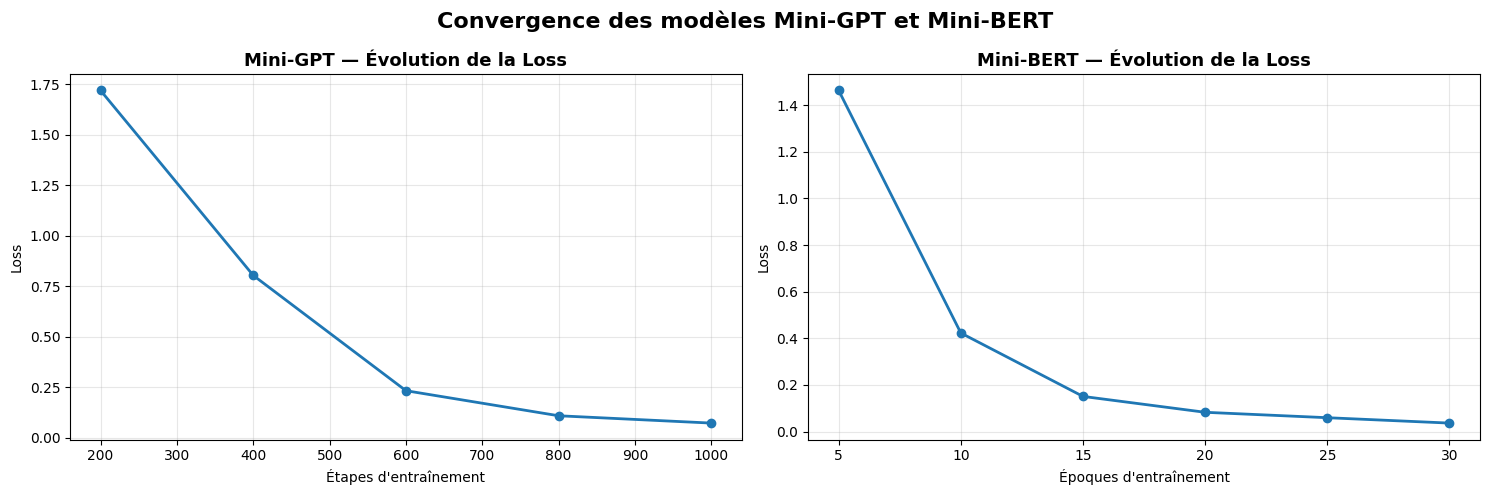

In [28]:

import matplotlib.pyplot as plt

# Résultats Mini-GPT
gpt_steps = [200, 400, 600, 800, 1000]
gpt_loss = [1.7199, 0.8036, 0.2325, 0.1083, 0.0720]

# Résultats Mini-BERT
bert_epochs = [5, 10, 15, 20, 25, 30]
bert_loss = [1.4628, 0.4228, 0.1510, 0.0829, 0.0597, 0.0366]

# Création de la figure
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Mini-GPT
axes[0].plot(gpt_steps, gpt_loss, marker='o', linewidth=2)
axes[0].set_title("Mini-GPT — Évolution de la Loss", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Étapes d'entraînement")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)

# Mini-BERT
axes[1].plot(bert_epochs, bert_loss, marker='o', linewidth=2)
axes[1].set_title("Mini-BERT — Évolution de la Loss", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Époques d'entraînement")
axes[1].set_ylabel("Loss")
axes[1].grid(True, alpha=0.3)

# Titre général
fig.suptitle(
    "Convergence des modèles Mini-GPT et Mini-BERT",
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()

# Sauvegarde
plt.savefig(
    "results/screenshots/06_training_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
